&nbsp;

## [ENCODE-rE2G](https://github.com/EngreitzLab/ENCODE_rE2G) Result Parse Notebook

- [config_biosamples_hs_atacseq_hic_list.tsv](../../out/ENCODE_rE2G/config/config_biosamples_hs_atacseq_hic_list.tsv)で定義した14個のデータセットでの enhancer-gene interaction の相互作用の結果をパースする notebook
- [ENCODE-rE2G](https://github.com/EngreitzLab/ENCODE_rE2G) での予測結果のうち、positive control となりそうな例について深堀りする

In [1]:
import re
import os
import pathlib
import datetime
import subprocess
import polars as pl
from IPython.display import display
from IPython.display import Image

pl.Config.set_fmt_str_lengths(200)
os.environ["POLARS_MAX_THREADS"] = "16"

In [2]:
execute_date = datetime.datetime.now().strftime("%y%m%d")  # noqa: DTZ005
print(f"Execute Date: {execute_date}")

Execute Date: 261003


&nbsp;

&nbsp;

&nbsp;

&nbsp;

## ENCODE-rE2G Filter Result (heat-stressed dataset)

- [./02_encode_re2g_parse_hs.ipynb](./02_encode_re2g_parse_hs.ipynb) で解析したデータ

In [3]:
e2g_join = pl.read_parquet(
    "../../out/ENCODE_rE2G/parquet_file/encode_re2g_hs_join_v261003.parquet"
)

display(e2g_join)

ENCODE-rE2G.Score,re2g_dataset,cre_id,cre_name,cre_chr,fantabio_cre_class,enhancer_cre_overlap_bp,enhancer_cre_overlap_frac_of_fantabio_cre,TargetGene,target_cre_id,target_cre_name,target_fantabio_cre_class,class,isSelfPromoter,distanceToTSS,re2g_enhancer_locus,fantabio_enhancer_cre,re2g_features,target_tss_info,target_cre_info,target_cre_overlap_info
f64,str,str,str,str,str,i64,f64,str,str,str,str,str,bool,f64,struct[3],struct[3],struct[8],struct[5],struct[10],struct[2]
0.999461,"""GSE105028_hESC_42C_60min""","""FCHS_100""","""cp6@KLHL17""","""chr1""","""ELA""",476,1.0,"""KLHL17""","""FCHS_98""","""cp3@KLHL17,cp7@NOC2L""","""PLA""","""promoter""",true,457.5,"{""chr1"",960336,961751}","{960949,961425,-0.483871}","{960586,""ENSG00000187961"",null,0.576527,0.236217,0,0,170.367064}","{""chr1"",960336,960836,0,""+""}","{""chr1"",960174,960791,0,""."",960534,960591,""204,0,0"",""directionality:0.864177|class:PLA"",0.864177}","{455,0.91}"
0.999857,"""GSE173536_lymphblastoid_d21_42C_60min""","""FCHS_100""","""cp6@KLHL17""","""chr1""","""ELA""",476,1.0,"""KLHL17""","""FCHS_98""","""cp3@KLHL17,cp7@NOC2L""","""PLA""","""promoter""",true,364.0,"{""chr1"",960335,961565}","{960949,961425,-0.483871}","{960586,""ENSG00000187961"",0.478225,null,0.259602,0,0,209.961424}","{""chr1"",960336,960836,0,""+""}","{""chr1"",960174,960791,0,""."",960534,960591,""204,0,0"",""directionality:0.864177|class:PLA"",0.864177}","{455,0.91}"
0.999926,"""GSE173536_lymphblastoid_t21_42C_60min""","""FCHS_100""","""cp6@KLHL17""","""chr1""","""ELA""",293,0.615546,"""KLHL17""","""FCHS_98""","""cp3@KLHL17,cp7@NOC2L""","""PLA""","""promoter""",true,196.5,"{""chr1"",960323,961242}","{960949,961425,-0.483871}","{960586,""ENSG00000187961"",0.461337,null,0.259602,0,0,233.348032}","{""chr1"",960336,960836,0,""+""}","{""chr1"",960174,960791,0,""."",960534,960591,""204,0,0"",""directionality:0.864177|class:PLA"",0.864177}","{455,0.91}"
0.999851,"""GSE267931_HUVEC_39C_120min""","""FCHS_100""","""cp6@KLHL17""","""chr1""","""ELA""",476,1.0,"""KLHL17""","""FCHS_98""","""cp3@KLHL17,cp7@NOC2L""","""PLA""","""promoter""",true,371.0,"{""chr1"",960336,961578}","{960949,961425,-0.483871}","{960586,""ENSG00000187961"",0.501016,null,0.259602,0,0,415.927582}","{""chr1"",960336,960836,0,""+""}","{""chr1"",960174,960791,0,""."",960534,960591,""204,0,0"",""directionality:0.864177|class:PLA"",0.864177}","{455,0.91}"
0.999568,"""GSE154744_K562_42C_25min""","""FCHS_1000""","""cp2@RER1""","""chr1""","""ELA""",378,0.574468,"""MORN1""","""FCHS_999""","""cp1@MORN1,cp1@RER1""","""PLA""","""promoter""",true,701.0,"{""chr1"",2392202,2392702}","{2392324,2392982,0.0}","{2391751,""ENSG00000116151"",0.859092,null,0.207712,0,0,1270.747782}","{""chr1"",2391501,2392001,0,""-""}","{""chr1"",2391399,2392038,0,""."",2391554,2391837,""0,0,0"",""directionality:-0.131564|class:PLA"",-0.131564}","{500,1.0}"
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
0.999937,"""GSE101731_HFF_44C_120min""","""FCHS_99994""","""cp1@LRRIQ1""","""chr12""","""ELA""",96,1.0,"""TSPAN19""","""FCHS_99993""","""cp4@LRRIQ1,cp3@TSPAN19""","""PLA""","""promoter""",true,146.0,"{""chr12"",85036027,85036819}","{85036596,85036692,0.333333}","{85036277,""ENSG00000231738"",0.410312,null,0.192534,0,0,0.0}","{""chr12"",85036027,85036527,0,""-""}","{""chr12"",85036236,85036498,0,""."",85036260,85036344,""204,0,0"",""directionality:0.970459|class:PLA"",0.970459}","{262,0.524}"
0.999844,"""GSE101731_HFF_44C_60min""","""FCHS_99994""","""cp1@LRRIQ1""","""chr12""","""ELA""",96,1.0,"""TSPAN19""","""FCHS_99993""","""cp4@LRRIQ1,cp3@TSPAN19""","""PLA""","""promoter""",true,318.5,"{""chr12"",85036027,85037164}","{85036596,85036692,0.333333}","{85036277,""ENSG00000231738"",0.464773,null,0.192534,0,0,0.0}","{""chr12"",85036027,85036527,0,""-""}","{""chr12"",85036236,85036498,0,""."",85036260,85036344,""204,0,0"",""directionality:0.970459|class:PLA"",0.970459}","{262,0.524}"
0.999993,"""GSE173536_lymphblastoid_d21_42C_60min""","""FCHS_99994""","""cp1@LRRIQ1""","""chr1

&nbsp;

&nbsp;

&nbsp;

&nbsp;

## 7.  Enhancer-target Region Unique Count

- enhancer 側で統合した `fanta.bio` の `cre_id` と Target 側の領域として統合した `fanta.bio`の `target_cre_id` の unique pair をカウントする
- `re2g_dataset` カラムのカウントも行う

In [4]:
e2g_join_unique_count = e2g_join.group_by(
    "cre_id",
    "fantabio_cre_class",
    "target_cre_id",
    "target_fantabio_cre_class",
    # "isSelfPromoter" (この値は遺伝子ごとに異なるのでグループ化しない)
).agg(
    pl.col("re2g_dataset").unique().alias("re2g_dataset"),
    pl.col("re2g_dataset").n_unique().alias("re2g_dataset_count"),
    pl.col("ENCODE-rE2G.Score").alias("ENCODE-rE2G.Score"),
    
    pl.col("ENCODE-rE2G.Score").min().alias("ENCODE-rE2G.Score_min"),
    pl.col("ENCODE-rE2G.Score").max().alias("ENCODE-rE2G.Score_max"),
    pl.col("ENCODE-rE2G.Score").mean().alias("ENCODE-rE2G.Score_mean"),

    # pl.col("ENCODE-rE2G.Score").quantile(0.25).alias("ENCODE-rE2G.Score_q1"),
    # pl.col("ENCODE-rE2G.Score").median().alias("ENCODE-rE2G.Score_median"),
    # pl.col("ENCODE-rE2G.Score").quantile(0.75).alias("ENCODE-rE2G.Score_q3"),
    # pl.col("ENCODE-rE2G.Score").std().alias("ENCODE-rE2G.Score_std"),
    
).sort(
    by=["re2g_dataset_count"],
    descending=True
)


print(f"ENCODE-rE2G enhancer - target region interaction unique pair count: {e2g_join_unique_count.select(['cre_id', 'target_cre_id']).n_unique()}")
display(e2g_join_unique_count)

ENCODE-rE2G enhancer - target region interaction unique pair count: 423357


cre_id,fantabio_cre_class,target_cre_id,target_fantabio_cre_class,re2g_dataset,re2g_dataset_count,ENCODE-rE2G.Score,ENCODE-rE2G.Score_min,ENCODE-rE2G.Score_max,ENCODE-rE2G.Score_mean
str,str,str,str,list[str],u32,list[f64],f64,f64,f64
"""FCHS_182600""","""PLA""","""FCHS_182599""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",14,"[0.999927, 0.999851, … 0.999861]",0.986819,0.999927,0.998384
"""FCHS_384968""","""PLA""","""FCHS_384968""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",14,"[0.999857, 0.999832, … 0.999863]",0.993615,0.999904,0.998942
"""FCHS_154527""","""PLA""","""FCHS_154527""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",14,"[0.999804, 0.999973, … 0.999214]",0.989354,0.999973,0.998295
"""FCHS_198558""","""PLA""","""FCHS_198558""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",14,"[0.999874, 1.0, … 0.999813]",0.995157,1.0,0.999444
"""FCHS_436861""","""ELA""","""FCHS_436862""","""PLA""","[""GSE101731_HFF_44C_120min"", ""GSE101731_HFF_44C_60min"", … ""GSE280307_THP1_42C_120min""]",14,"[0.999891, 0.999927, … 0.99999]",0.99305,0.99999,0.999245
…,…,…,…,…,…,…,…,…,…
"""FCHS_475880""","""PLA""","""FCHS_88903""","""PLA""","[""GSE173536_lymphblastoid_d21_42C_60min""]",1,[0.20203],0.20203,0.20203,0.20203
"""FCHS_287557""","""ELA""","""FCHS_287515""","""PLA""","[""GSE209675_MCF7_42C_60min""]",1,[0.258082],0.258082,0.258082,0.258082
"""FCHS_209218""","""PLA""","""FCHS_209134""","""PLA""","[""GSE267931_HUVEC_39C_120min""]",1,[0.211247],0.211247,0.211247,0.211247


&nbsp;

&nbsp;

&nbsp;

&nbsp;

&nbsp;

&nbsp;

&nbsp;

&nbsp;

## Specific Example (1) [FCHS_571903](https://fanta.bio/cre/FCHS_571903) (Positive Control)

- [Stress-induced transcriptional memory accelerates promoter-proximal pause release and decelerates termination over mitotic divisions](https://doi.org/10.1016/j.molcel.2021.03.007) という論文 (この論文で作成されたATAC-seq などのデータセットを ENCODE-rE2G でも使用している) では、以下のような例が紹介されている
- [_TAX1BP1_](https://genenames.org/data/gene-symbol-report/#!/hgnc_id/HGNC:11575) の近傍のプロモーターには HSF1 は結合せず、その上流の 4.5kb 程度にある エンハンサーにHSF1が結合していることが報告されている
- この報告を positive control として使用できないか検証
- ゲノムブラウザーを見ながら、上流 のシスエレメント を見ていった
- 今のところ、[FCHS_571903](https://fanta.bio/cre/FCHS_571903)が最有力候補
- [FCHS_571900](https://fanta.bio/cre/FCHS_571900)も相互作用が予測されていることに注意

&nbsp;

&nbsp;

## (1) _TAX1BP1_ の メタ解析結果 確認

- `fanta.bio` との CRE 統合後の結果を確認
- 更に、ChIP-Atlas Diff Analysis による結果のフィルタリング後の結果とも確認

In [5]:
up5p_fantabio_cre = pl.read_parquet(
    "../../out/fantabio/parquet_file/up5p_transcript_fantabio_v261001.parquet"
)

pl.Config.set_tbl_rows(2)
display(up5p_fantabio_cre)

transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str
"""ENST00000309758.6""",352,17,37,335,232,4,15,228,"""HSPA6""","""HGNC:5239""","""protein_coding""","""ENSG00000173110.8""","[""basic"", ""Ensembl_canonical"", … ""CCDS""]","""+""",6,null,null,null,"""ensembl_havana_gene_homo_sapiens""","[""MANE_select""]",1,"""FCHS_28105""","""chr1""",161523745,"""161524487""","""cp1@HSPA6""","[""GQ891451""]","""0""",53,"[{""EH38E2843853"",""pELS""}, {""EH38E2843855"",""PLS""}, {""EH38E3981533"",""pELS""}]","[{""STAG2"",4103,[{""SRX9975614"",4103}, {""SRX9975613"",3500}, {""SRX26159208"",562}]}, {""HSF1"",4038,[{""SRX16646095"",4038}, {""SRX16646111"",3572}, … {""SRX13845684"",554}]}, … {""GABPA"",500,[{""SRX2635792"",500}]}]","[{""HS_00013400"",""H1 BMP4 Derived Mesendoderm Cultured Cells"",""Mesendoderm cell"",""Others"",""SVM""}, {""HS_00013401"",""H1 Cells"",""Embryonic stem cell"",""Stem cell"",""SVM""}, … {""HS_00013403"",""Foreskin Fibroblast Primary Cells skin02"",""Prepuce"",""Skin"",""SVM""}]",null,null,0.982111,"""PLA""","""204,0,0""","""red"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ENST00000774581.1""",101,57,248,44,34,44,173,-10,null,null,"""lncRNA""","""ENSG00000300853.1""","[""basic"", ""TAGENE""]","""+""",2,"""URS0002A25289""","""ENSEMBL_GENCODE""",null,"""havana_tagene_homo_sapiens""","[""CLS3 project""]",1,"""FCHS_400104""","""chr8""",27592922,"""27593122""","""FCHS_400104""","[""ENST00000774579.1""]","""0""",294,"[{""EH38E3824983"",""dELS""}]",null,"[{""HS_00105821"",""NHEK-Epidermal Keratinocyte Primary Cells"",""Skin"",""Skin"",""SVM""}, {""HS_00105822"",""H1 BMP4 Derived Trophoblast Cultured Cells"",""Trophoblast cell"",""Others"",""SVM""}, … {""HS_00105828"",""Breast variant Human Mammary Epithelial Cells (vHMEC)"",""Breast"",""Breast"",""SVM""}]",null,null,0.5,"""ELA""","""255,202,74""","""yellow"""


In [33]:
# After Diff Analysis
up5p_cre_diff_analysis = pl.read_parquet(
    "../../out/ChIP-Atlas_diff/diff_analysis_filter_parquet/transcript_cre/fantabio_HN2_up5p_v261002_diff_analysis_atac.parquet"
)

pl.Config.set_tbl_rows(2)
display(up5p_cre_diff_analysis)

transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name,cre_start,cre_end,overlap_frac_of_fantabio_cre,dpr_interval,log2fc,p_value,q_value,diff_dataset,diff_dataset_count,source_bed_file
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str,i64,i64,list[f64],list[struct[3]],list[f64],list[f64],list[f64],list[str],u32,list[str]
"""ENST00000309758.6""",352,17,37,335,232,4,15,228,"""HSPA6""","""HGNC:5239""","""protein_coding""","""ENSG00000173110.8""","[""basic"", ""Ensembl_canonical"", … ""CCDS""]","""+""",6,null,null,null,"""ensembl_havana_gene_homo_sapiens""","[""MANE_select""]",1,"""FCHS_28105""","""chr1""",161523745,"""161524487""","""cp1@HSPA6""","[""GQ891451""]","""0""",53,"[{""EH38E2843853"",""pELS""}, {""EH38E2843855"",""PLS""}, {""EH38E3981533"",""pELS""}]","[{""STAG2"",4103,[{""SRX9975614"",4103}, {""SRX9975613"",3500}, {""SRX26159208"",562}]}, {""HSF1"",4038,[{""SRX16646095"",4038}, {""SRX16646111"",3572}, … {""SRX13845684"",554}]}, … {""GABPA"",500,[{""SRX2635792"",500}]}]","[{""HS_00013400"",""H1 BMP4 Derived Mesendoderm Cultured Cells"",""Mesendoderm cell"",""Others"",""SVM""}, {""HS_00013401"",""H1 Cells"",""Embryonic stem cell"",""Stem cell"",""SVM""}, … {""HS_00013403"",""Foreskin Fibroblast Primary Cells skin02"",""Prepuce"",""Skin"",""SVM""}]",null,null,0.982111,"""PLA""","""204,0,0""","""red""",161523744,161524487,"[0.296097, 0.117093, 0.351279]","[{161524223,161524443,""chr1""}, {161524400,161524568,""chr1""}, {161524226,161524581,""chr1""}]","[1.209197, 1.832055, 1.892709]","[2.7404e-8, 1.8112e-16, 7.5870e-7]","[0.000001, 2.0457e-12, 0.000487]","[""GSE101731_atac_hff_44C_120min"", ""GSE173536_atac_d21_42C_60min"", ""GSE209675_mcf7_42C_60min""]",3,"[""GSE101731_atac_hff_44C_120min_intersecting_human-CREv1.2.1.hg38.cre-peaks.bed"", ""GSE173536_atac_d21_42C_60min_intersecting_human-CREv1.2.1.hg38.cre-peaks.bed"", ""GSE209675_mcf7_42C_60min_intersecting_human-CREv1.2.1.hg38.cre-peaks.bed""]"
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ENST00000678039.1""",102,58,246,44,50,45,156,5,"""RPS20""","""HGNC:10405""","""nonsense_mediated_decay""","""ENSG00000008988.12""","[""RNA_Seq_supported_only"", ""CCDS""]","""-""",2,null,null,null,"""ensembl_havana_gene_homo_sapiens""","[""RNA-Seq supported only""]",1,"""FCHS_403770""","""chr8""",56074307,"""56074825""","""cp1@CERNA3,cp2@RPS20""","[""ENST00000676461.1"", ""ENST00000519807.5"", … ""D28358""]","""0""",0,"[{""EH38E2632426"",""pELS""}, {""EH38E3834665"",""PLS""}, {""EH38E3834666"",""PLS""}]","[{""CTCF"",4378,[{""SRX8622036"",4378}, {""SRX10975999"",4357}, … {""SRX102986"",501}]}, {""ZBTB11"",4051,[{""SRX15898392"",4051}, {""SRX2424560"",3514}, … {""SRX2630262"",766}]}, … {""ZNF668"",502,[{""SRX10977254"",502}]}]","[{""HS_00108611"",""HepG2"",""Liver"",""Liver"",""SVM""}, {""HS_00108612"",""Fetal Intestine Large"",""Large intestine"",""Intestine"",""SVM""}, … {""HS_00108615"",""HMEC Mammary Epithelial Primary Cells"",""Mammary gland"",""Breast"",""SVM""}]","[{""hg19::chr8:56987057..56987058,-;hg_93135.1"",""p2@RPS20""}, {""hg19::chr8:56987059..56987060,-;hg_93136.1"",""p3@RPS20""}, … {""hg38::chr8:56074312..56074321,-;hg_231159.1"",""p5@RPS20""}]",null,-0.999715,"""PLA""","""0,0,204""","""blue""",56074306,56074825,[0.119461],"[{56074333,56074395,""chr8"

In [6]:
TAX1BP1_up5p_cre = up5p_fantabio_cre.filter(
    pl.col("HGNC_ID") == "HGNC:11575"
)

pl.Config.set_tbl_rows(6)
print(TAX1BP1_up5p_cre.select("cre_id").unique())

pl.Config.set_tbl_rows(2)
display(TAX1BP1_up5p_cre)

shape: (6, 1)
┌─────────────┐
│ cre_id      │
│ ---         │
│ str         │
╞═════════════╡
│ FCHS_571906 │
│ FCHS_571905 │
│ FCHS_378087 │
│ FCHS_378109 │
│ FCHS_378089 │
│ FCHS_378090 │
└─────────────┘


transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str
"""ENST00000460059.1""",235,29,142,206,165,8,78,157,"""TAX1BP1""","""HGNC:11575""","""protein_coding_CDS_not_defined""","""ENSG00000106052.15""","[""exp_conf""]","""+""",1,null,null,null,"""ensembl_havana_gene_homo_sapiens""",null,0,"""FCHS_378109""","""chr7""",27828861,"""27829156""","""FCHS_378109""","[""LF362464"", ""MA598041""]","""0""",-161,null,"[{""EZH2"",672,[{""SRX2146136"",672}]}]","[{""HS_01187980"",""Primary T cells from peripheral blood"",""Blood"",""Blood"",""gkmSVM""}, {""HS_01187981"",""H1 Derived Neuronal Progenitor Cultured Cells"",""Brain"",""Brain"",""gkmSVM""}, {""HS_01187982"",""HMEC Mammary Epithelial Primary Cells"",""Mammary gland"",""Breast"",""gkmSVM""}]",null,null,0.496403,"""ELA""","""255,202,74""","""yellow"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ENST00000871717.1""",88,32,286,56,49,17,185,32,"""TAX1BP1""","""HGNC:11575""","""protein_coding""","""ENSG00000106052.15""","[""basic"", ""TAGENE"", ""CCDS""]","""+""",3,null,null,null,"""ensembl_havana_gene_homo_sapiens""","[""DanaFarber""]",1,"""FCHS_571906""","""chr7""",27740733,"""27740818""","""FCHS_571906""","[""LF207148"", ""MA442725""]","""-56""",-144,"[{""EH38E3764011"",""pELS""}]","[{""GFP"",2347,[{""SRX12204161"",2347}, {""SRX12204160"",936}, … {""SRX1514953"",521}]}, {""TFAP4"",2310,[{""SRX1892834"",2310}, {""SRX1892835"",2024}, … {""SRX20420565"",505}]}, … {""SETD2"",500,[{""SRX18954640"",500}]}]","[{""HS_00089028"",""Psoas Muscle"",""Muscle"",""Muscle"",""SVM""}, {""HS_00089029"",""Fetal Brain Female"",""Brain"",""Brain"",""SVM""}, … {""HS_03039990"",""HepG2"",""Liver"",""Liver"",""High throughput""}]","[{""hg19::chr7:27780352..27780370,-;hg_83352.1"",""hg_83352.1""}]",null,-0.958042,"""PLA""","""0,0,204""","""blue"""


In [36]:
TAX1BP1_up5p_cre_diff_analysis = up5p_cre_diff_analysis.filter(
    pl.col("HGNC_ID") == "HGNC:11575"
)

pl.Config.set_tbl_rows(6)
display(TAX1BP1_up5p_cre_diff_analysis)

transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name,cre_start,cre_end,overlap_frac_of_fantabio_cre,dpr_interval,log2fc,p_value,q_value,diff_dataset,diff_dataset_count,source_bed_file
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str,i64,i64,list[f64],list[struct[3]],list[f64],list[f64],list[f64],list[str],u32,list[str]
"""ENST00000916540.1""",144,27,235,117,74,10,167,64,"""TAX1BP1""","""HGNC:11575""","""protein_coding""","""ENSG00000106052.15""","[""basic"", ""TAGENE""]","""+""",2,null,null,null,"""ensembl_havana_gene_homo_sapiens""","[""LRGASP""]",1,"""FCHS_378089""","""chr7""",27739899,"""27740358""","""cp4@TAX1BP1,cp3@TAX1BP1-AS1""","[""ENST00000806472.1"", ""ENST00000806474.1"", … ""BC050358""]","""0""",0,"[{""EH38E3764009"",""PLS""}]","[{""GABPA"",3705,[{""SRX718130"",3705}, {""SRX3322176"",2547}, … {""SRX100469"",582}]}, {""GABPB1"",3161,[{""SRX5457278"",3161}, {""SRX5457277"",3105}, … {""SRX2635886"",1968}]}, … {""EHMT2"",504,[{""SRX4561210"",504}]}]","[{""HS_00089028"",""Psoas Muscle"",""Muscle"",""Muscle"",""SVM""}, {""HS_00089029"",""Fetal Brain Female"",""Brain"",""Brain"",""SVM""}, … {""HS_00089032"",""Foreskin Fibroblast Primary Cells skin02"",""Prepuce"",""Skin"",""SVM""}]","[{""hg19::chr7:27779729..27779819,+;hg_77829.1"",""p1@TAX1BP1""}]",null,0.997065,"""PLA""","""204,0,0""","""red""",27739898,27740358,[0.254348],"[{27740194,27740311,""chr7""}]",[1.880554],[2.9054e-8],[0.000001],"[""GSE101731_atac_hff_44C_120min""]",1,"[""GSE101731_atac_hff_44C_120min_intersecting_human-CREv1.2.1.hg38.cre-peaks.bed""]"
"""ENST00000422800.5""",131,44,231,87,78,21,152,57,"""TAX1BP1""","""HGNC:11575""","""protein_coding""","""ENSG00000106052.15""","[""alternative_5_UTR"", ""mRNA_end_NF"", ""cds_end_NF""]","""+""",3,null,null,null,"""ensembl_havana_gene_homo_sapiens""","[""alternative 5' UTR""]",1,"""FCHS_378089""","""chr7""",27739899,"""27740358""","""cp4@TAX1BP1,cp3@TAX1BP1-AS1""","[""ENST00000806472.1"", ""ENST00000806474.1"", … ""BC050358""]","""0""",-297,"[{""EH38E3764009"",""PLS""}]","[{""GABPA"",3705,[{""SRX718130"",3705}, {""SRX3322176"",2547}, … {""SRX100469"",582}]}, {""GABPB1"",3161,[{""SRX5457278"",3161}, {""SRX5457277"",3105}, … {""SRX2635886"",1968}]}, … {""EHMT2"",504,[{""SRX4561210"",504}]}]","[{""HS_00089028"",""Psoas Muscle"",""Muscle"",""Muscle"",""SVM""}, {""HS_00089029"",""Fetal Brain Female"",""Brain"",""Brain"",""SVM""}, … {""HS_00089032"",""Foreskin Fibroblast Primary Cells skin02"",""Prepuce"",""Skin"",""SVM""}]","[{""hg19::chr7:27779729..27779819,+;hg_77829.1"",""p1@TAX1BP1""}]",null,0.997065,"""PLA""","""204,0,0""","""red""",27739898,27740358,[0.254348],"[{27740194,27740311,""chr7""}]",[1.880554],[2.9054e-8],[0.000001],"[""GSE101731_atac_hff_44C_120min""]",1,"[""GSE101731_atac_hff_44C_120min_intersecting_human-CREv1.2.1.hg38.cre-peaks.bed""]"
"""ENST00000945738.1""",148,70,188,78,99,35,117,64,"""TAX1BP1""","""HGNC:11575""","""protein_coding""","""ENSG00000106052.15""","[""basic"", ""TAGENE""]","""+""",2,null,null,null,"""ensembl_havana_gene_homo_sapiens""","[""ENCODE_tissue""]",1,"""FCHS_378089""","""chr7""",27739899,"""27740358""","""cp4@TAX1BP1,cp3@TAX1BP1-AS1""","[""ENST00000806472.1"", ""ENST00000806474.1"", … ""BC050358""]","""0""",0,"[{""EH38E3764009"",""PLS""}]","[{""GABPA"",3705,[{""SRX718130"",3705}, {""SRX3322176"",2547}, … {"

In [7]:
TAX1BP1_proximal_cre_list = [
    "FCHS_378089",
    "FCHS_378087",
    "FCHS_378109",
    "FCHS_571905",
    "FCHS_378090",
    "FCHS_571906"
]

&nbsp;

&nbsp;

&nbsp;

&nbsp;

## (2) _TAX1BP1_ の 近傍の CRE の metadata check

- HSF1 が結合するポテンシャルがあるかチェック

In [8]:
# 近傍に Ensembl transcript ID があるかどうかはフィルタリング条件には使用していない
fantabio_cre_human_metadata = pl.read_ndjson(
    "../../Data/Database/fantabio/human-CREv1.2.1.hg38.cre-peaks_annotation.jsonl.gz"
).drop(
    "cre_old_names",
    "tss_ncbi_geneids",
    "tss_hgnc_mgi_ids",
    "tss_uniprot_ids",
    "tss_gene_names",
    "tss_gene_symbols",
    "tss_gene_synonyms",
    "tss_gene_sources"
).with_columns(
    # Q-score は後々フィルタリングの条件に使うかもしれないため、cast(pl.Int64) で整数型に変換しておく
    # print(fanta_bio_human_metadata["chip_atlas_antigens"].dtype) で確認できる
    pl.col("chip_atlas_antigens").list.eval(
        pl.struct([
            pl.element().struct.field("antigen").alias("antigen"),
            pl.element().struct.field("maxqscore").cast(pl.Int64).alias("maxqscore"),
            pl.element().struct.field("experiments").list.eval(
                pl.struct([
                    pl.element().struct.field("id").alias("id"),
                    pl.element().struct.field("qscore").cast(pl.Int64).alias("qscore"),
                ])
            ).alias("experiments"),
        ])
    ).alias("chip_atlas_antigens"),
)

pl.Config.set_tbl_rows(2)
print(fantabio_cre_human_metadata.select("cre_id").n_unique())
display(fantabio_cre_human_metadata)

513895


cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,tss_transcripts,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers
str,str,i64,str,str,list[str],str,list[struct[2]],list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]]
"""FCHS_1""","""chr1""",10610,"""10687""","""cp1@DDX11L1""","[""ENST00000832824.1""]","""434""","[{""ENST00000832824.1"",""434""}, {""ENST00000832825.1"",""438""}]","[{""EH38E2776517"",""pELS""}]","[{""EGR1"",2552,[{""SRX22828712"",2552}, {""SRX22828708"",1544}, {""SRX22828709"",1187}]}, {""BRD3"",1874,[{""SRX366792"",1874}, {""SRX366793"",621}, {""SRX366794"",537}]}, … {""NRF1"",807,[{""SRX2636389"",807}, {""SRX23881992"",770}, {""SRX1280449"",580}]}]",null,null,null
…,…,…,…,…,…,…,…,…,…,…,…,…
"""FCHS_593940""","""chrY""",56881615,"""56881922""","""FCHS_593940""","[""ENST00000810723.1""]","""0""","[{""ENST00000810723.1"",""0""}]",null,"[{""RELA"",1452,[{""SRX5938177"",1452}]}, {""RNF2"",939,[{""SRX18954702"",939}, {""SRX18954704"",699}]}, … {""DLX5"",504,[{""SRX17306262"",504}]}]",null,"[{""hg19::chrY:59027988..59028000,+;hg_201233.1"",""hg_201233.1""}]",null


In [9]:
TAX1BP1_proximal_cre = fantabio_cre_human_metadata.filter(
    pl.col("cre_id").is_in(TAX1BP1_proximal_cre_list)
)

pl.Config.set_tbl_rows(6)
display(TAX1BP1_proximal_cre)

cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,tss_transcripts,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers
str,str,i64,str,str,list[str],str,list[struct[2]],list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]]
"""FCHS_378087""","""chr7""",27739331,"""27739553""","""cp1@TAX1BP1""","[""ENST00000418691.5"", ""ENST00000543117.5"", … ""AK299729""]","""0""","[{""ENST00000418691.5"",""0""}, {""ENST00000543117.5"",""0""}, … {""ENST00000422800.5"",""49""}]","[{""EH38E2543088"",""PLS""}]","[{""GFP"",584,[{""SRX1515030"",584}]}]","[{""HS_00089028"",""Psoas Muscle"",""Muscle"",""Muscle"",""SVM""}, {""HS_00089029"",""Fetal Brain Female"",""Brain"",""Brain"",""SVM""}, … {""HS_00089032"",""Foreskin Fibroblast Primary Cells skin02"",""Prepuce"",""Skin"",""SVM""}]",null,null
"""FCHS_378089""","""chr7""",27739899,"""27740358""","""cp4@TAX1BP1,cp3@TAX1BP1-AS1""","[""ENST00000806472.1"", ""ENST00000806474.1"", … ""BC050358""]","""0""","[{""ENST00000806472.1"",""0""}, {""ENST00000806474.1"",""0""}, … {""NR_187572.1"",""-317""}]","[{""EH38E3764009"",""PLS""}]","[{""GABPA"",3705,[{""SRX718130"",3705}, {""SRX3322176"",2547}, … {""SRX100469"",582}]}, {""GABPB1"",3161,[{""SRX5457278"",3161}, {""SRX5457277"",3105}, … {""SRX2635886"",1968}]}, … {""EHMT2"",504,[{""SRX4561210"",504}]}]","[{""HS_00089028"",""Psoas Muscle"",""Muscle"",""Muscle"",""SVM""}, {""HS_00089029"",""Fetal Brain Female"",""Brain"",""Brain"",""SVM""}, … {""HS_00089032"",""Foreskin Fibroblast Primary Cells skin02"",""Prepuce"",""Skin"",""SVM""}]","[{""hg19::chr7:27779729..27779819,+;hg_77829.1"",""p1@TAX1BP1""}]",null
"""FCHS_378090""","""chr7""",27740368,"""27740731""","""cp7@TAX1BP1,cp2@TAX1BP1-AS1""","[""ENST00000441955.2"", ""ENST00000945749.1"", … ""NR_187572.1""]","""0""","[{""ENST00000441955.2"",""0""}, {""ENST00000945749.1"",""0""}, … {""MA619688"",""-273""}]","[{""EH38E3764010"",""PLS""}, {""EH38E3764011"",""pELS""}]","[{""GFP"",2347,[{""SRX12204161"",2347}, {""SRX5874023"",961}, … {""SRX1514979"",894}]}, {""TFAP4"",2310,[{""SRX1892834"",2310}, {""SRX1892835"",2024}, … {""SRX20420573"",542}]}, … {""CHD8"",500,[{""SRX534844"",500}]}]","[{""HS_00089028"",""Psoas Muscle"",""Muscle"",""Muscle"",""SVM""}, {""HS_00089029"",""Fetal Brain Female"",""Brain"",""Brain"",""SVM""}, … {""HS_03039990"",""HepG2"",""Liver"",""Liver"",""High throughput""}]","[{""hg19::chr7:27780248..27780295,-;hg_83351.1"",""hg_83351.1""}]",null
"""FCHS_378109""","""chr7""",27828861,"""27829156""","""FCHS_378109""","[""LF362464"", ""MA598041""]","""0""","[{""LF362464"",""0""}, {""MA598041"",""0""}, … {""MA598038"",""-453""}]",null,"[{""EZH2"",672,[{""SRX2146136"",672}]}]","[{""HS_01187980"",""Primary T cells from peripheral blood"",""Blood"",""Blood"",""gkmSVM""}, {""HS_01187981"",""H1 Derived Neuronal Progenitor Cultured Cells"",""Brain"",""Brain"",""gkmSVM""}, {""HS_01187982"",""HMEC Mammary Epithelial Primary Cells"",""Mammary gland"",""Breast"",""gkmSVM""}]",null,null
"""FCHS_571905""","""chr7""",27739448,"""27739821""","""cp6@TAX1BP1""","[""ENST00000422800.5""]","""0""","[{""ENST00000422800.5"",""0""}, {""ENST00000543117.5"",""-75""}, … {""BC050358"",""389""}]","[{""EH38E2543088"",""PLS""}, {""EH38E2543089"",""pELS""}]","[{""CTCF"",1757,[{""SRX12008350"",1757}, {""SRX12008355"",1249}, {""SRX13551281"",988}]}, {""TP63"",711,[{""SRX19885676"",711}]}]","[{""HS_00089028"",""Psoas Muscle"",""Muscle"",""Muscle"",""SVM""}, {""HS_00089029"",""Fetal Brain Female"",""Brain"",""Brain"",""SVM""}, … {""HS_00089032"",""Foreskin Fibroblast Primary Cells skin02"",""Prepuce"",""Skin"",""SVM""}]",null,null
"""FCHS_571906""","""chr7""",27740733,"""27740818""","""FCHS_571906""","[""LF207148"", ""MA442725""]","""-56""","[{""LF207148"",""-56""}, {""MA442725"",""-56""}, … {""ENST00000441955.2"",""338""}]","[{""EH38E3764011"",""pELS""}]","[{""GFP"",2347,[{""SRX12204161"",2347}, {""SRX12204160"",936},

In [10]:
# Nested dtype shows field names (antigen, maxqscore, experiments)
print(TAX1BP1_proximal_cre.schema["chip_atlas_antigens"])
print(TAX1BP1_proximal_cre["chip_atlas_antigens"].dtype)

List(Struct({'antigen': String, 'maxqscore': Int64, 'experiments': List(Struct({'id': String, 'qscore': Int64}))}))
List(Struct({'antigen': String, 'maxqscore': Int64, 'experiments': List(Struct({'id': String, 'qscore': Int64}))}))


&nbsp;

&nbsp;

## (3) CHECK HSF1 Binding Poteintial

- TAX1BP1 の近傍の シスエレメントには、Heat Shock Factor 1 (HSF1) の結合ポテンシャルがないことを `fanta.bio`の JSON metadata から簡単にチェックする

In [11]:
# True if any nested antigen name equals HSF1; null antigen lists become False
TAX1BP1_proximal_cre = TAX1BP1_proximal_cre.with_columns(
    pl.when(
        pl.col("chip_atlas_antigens")
        .list.eval(pl.element().struct.field("antigen") == "HSF1")
        .list.any()
        .fill_null(False)
    )
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("has_HSF1"),
)

pl.Config.set_tbl_rows(6)
display(
    TAX1BP1_proximal_cre.select(
        "cre_id",
        "cre_name",
        "has_HSF1",
        "chip_atlas_antigens",
    )
)

cre_id,cre_name,has_HSF1,chip_atlas_antigens
str,str,bool,list[struct[3]]
"""FCHS_378087""","""cp1@TAX1BP1""",false,"[{""GFP"",584,[{""SRX1515030"",584}]}]"
"""FCHS_378089""","""cp4@TAX1BP1,cp3@TAX1BP1-AS1""",false,"[{""GABPA"",3705,[{""SRX718130"",3705}, {""SRX3322176"",2547}, … {""SRX100469"",582}]}, {""GABPB1"",3161,[{""SRX5457278"",3161}, {""SRX5457277"",3105}, … {""SRX2635886"",1968}]}, … {""EHMT2"",504,[{""SRX4561210"",504}]}]"
"""FCHS_378090""","""cp7@TAX1BP1,cp2@TAX1BP1-AS1""",false,"[{""GFP"",2347,[{""SRX12204161"",2347}, {""SRX5874023"",961}, … {""SRX1514979"",894}]}, {""TFAP4"",2310,[{""SRX1892834"",2310}, {""SRX1892835"",2024}, … {""SRX20420573"",542}]}, … {""CHD8"",500,[{""SRX534844"",500}]}]"
"""FCHS_378109""","""FCHS_378109""",false,"[{""EZH2"",672,[{""SRX2146136"",672}]}]"
"""FCHS_571905""","""cp6@TAX1BP1""",false,"[{""CTCF"",1757,[{""SRX12008350"",1757}, {""SRX12008355"",1249}, {""SRX13551281"",988}]}, {""TP63"",711,[{""SRX19885676"",711}]}]"
"""FCHS_571906""","""FCHS_571906""",false,"[{""GFP"",2347,[{""SRX12204161"",2347}, {""SRX12204160"",936}, … {""SRX1514953"",521}]}, {""TFAP4"",2310,[{""SRX1892834"",2310}, {""SRX1892835"",2024}, … {""SRX20420565"",505}]}, … {""SETD2"",500,[{""SRX18954640"",500}]}]"


&nbsp;

&nbsp;

&nbsp;

&nbsp;

## (4) Upstream Enhancer

- [Stress-induced transcriptional memory accelerates promoter-proximal pause release and decelerates termination over mitotic divisions](https://doi.org/10.1016/j.molcel.2021.03.007) という論文 (この論文で作成されたATAC-seq などのデータセットを ENCODE-rE2G でも使用している) では、以下のような例が紹介されている
- [_TAX1BP1_](https://genenames.org/data/gene-symbol-report/#!/hgnc_id/HGNC:11575) の近傍のプロモーターには HSF1 は結合せず、その上流の 4.5kb 程度にある エンハンサーにHSF1が結合していることが報告されている
- この報告を positive control として使用できないか検証
- ゲノムブラウザーを見ながら、上流 のシスエレメント を見ていった
- 今のところ、[FCHS_571903](https://fanta.bio/cre/FCHS_571903)が最有力候補
- [FCHS_571900](https://fanta.bio/cre/FCHS_571900)も相互作用が予測されていることを確認

&nbsp;

### 確認済み

- FCHS_378085
- FCHS_571902
- FCHS_571901

In [12]:
#check candidate no.1
# SCREEN Overlapped CRE: EH38E3764005: https://screen.wenglab.org/GRCh38/ccre/EH38E3764005
FCHS_571903 = e2g_join.filter(
    pl.col("cre_id") == "FCHS_571903"
)

FCHS_571903_metadata = fantabio_cre_human_metadata.filter(
    pl.col("cre_id") == "FCHS_571903"
).with_columns(
    pl.when(
        pl.col("chip_atlas_antigens")
        .list.eval(pl.element().struct.field("antigen") == "HSF1")
        .list.any()
        .fill_null(False)
    )
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("has_HSF1"),
)

FCHS_571903_e2g_join_unique_count = e2g_join_unique_count.filter(
    pl.col("cre_id") == "FCHS_571903"
)

pl.Config.set_tbl_rows(14)
display(FCHS_571903_metadata)
display(FCHS_571903_e2g_join_unique_count)
display(FCHS_571903)

cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,tss_transcripts,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,has_HSF1
str,str,i64,str,str,list[str],str,list[struct[2]],list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],bool
"""FCHS_571903""","""chr7""",27734628,"""27734903""","""FCHS_571903""",[],null,[],"[{""EH38E3764005"",""dELS""}]","[{""HSF1"",3486,[{""SRX16646095"",3486}, {""SRX16646111"",3316}, … {""SRX690824"",578}]}, {""SUMO2"",1912,[{""SRX895420"",1912}, {""SRX895419"",1713}]}, … {""STAT3"",560,[{""SRX347427"",560}]}]","[{""HS_01187824"",""HMEC Mammary Epithelial Primary Cells"",""Mammary gland"",""Breast"",""gkmSVM""}, {""HS_01187825"",""Transverse Colon"",""Colon"",""Intestine"",""gkmSVM""}, … {""HS_01187828"",""Transverse Colon"",""Colon"",""Intestine"",""gkmSVM""}]",null,"[{[""chr7:27734627-27734902""]}]",true


cre_id,fantabio_cre_class,target_cre_id,target_fantabio_cre_class,re2g_dataset,re2g_dataset_count,ENCODE-rE2G.Score,ENCODE-rE2G.Score_min,ENCODE-rE2G.Score_max,ENCODE-rE2G.Score_mean
str,str,str,str,list[str],u32,list[f64],f64,f64,f64
"""FCHS_571903""","""ELA""","""FCHS_378089""","""PLA""","[""GSE154744_K562_42C_25min"", ""GSE154744_K562_42C_30min"", … ""GSE280307_THP1_42C_120min""]",8,"[0.396576, 0.291939, … 0.625849]",0.281288,0.625849,0.396492


ENCODE-rE2G.Score,re2g_dataset,cre_id,cre_name,cre_chr,fantabio_cre_class,enhancer_cre_overlap_bp,enhancer_cre_overlap_frac_of_fantabio_cre,TargetGene,target_cre_id,target_cre_name,target_fantabio_cre_class,class,isSelfPromoter,distanceToTSS,re2g_enhancer_locus,fantabio_enhancer_cre,re2g_features,target_tss_info,target_cre_info,target_cre_overlap_info
f64,str,str,str,str,str,i64,f64,str,str,str,str,str,bool,f64,struct[3],struct[3],struct[8],struct[5],struct[10],struct[2]
0.396576,"""GSE154744_K562_42C_25min""","""FCHS_571903""","""FCHS_571903""","""chr7""","""ELA""",238,0.862319,"""TAX1BP1""","""FCHS_378089""","""cp4@TAX1BP1,cp3@TAX1BP1-AS1""","""PLA""","""intergenic""",false,5479.0,"{""chr7"",27734365,27734865}","{27734627,27734903,0.375}","{27740094,""ENSG00000106052"",0.900731,null,0.084905,1,1,1195.559684}","{""chr7"",27739844,27740344,0,""+""}","{""chr7"",27739898,27740358,0,""."",27740091,27740166,""204,0,0"",""directionality:0.997065|class:PLA"",0.997065}","{446,0.892}"
0.291939,"""GSE154744_K562_42C_30min""","""FCHS_571903""","""FCHS_571903""","""chr7""","""ELA""",276,1.0,"""TAX1BP1""","""FCHS_378089""","""cp4@TAX1BP1,cp3@TAX1BP1-AS1""","""PLA""","""intergenic""",false,5402.0,"{""chr7"",27734442,27734942}","{27734627,27734903,0.375}","{27740094,""ENSG00000106052"",0.902908,null,0.085683,1,1,1061.389686}","{""chr7"",27739844,27740344,0,""+""}","{""chr7"",27739898,27740358,0,""."",27740091,27740166,""204,0,0"",""directionality:0.997065|class:PLA"",0.997065}","{446,0.892}"
0.281288,"""GSE154744_K562_42C_30min_intact_hic""","""FCHS_571903""","""FCHS_571903""","""chr7""","""ELA""",276,1.0,"""TAX1BP1""","""FCHS_378089""","""cp4@TAX1BP1,cp3@TAX1BP1-AS1""","""PLA""","""intergenic""",false,5402.0,"{""chr7"",27734442,27734942}","{27734627,27734903,0.375}","{27740094,""ENSG00000106052"",0.902908,null,0.105664,1,1,1061.389686}","{""chr7"",27739844,27740344,0,""+""}","{""chr7"",27739898,27740358,0,""."",27740091,27740166,""204,0,0"",""directionality:0.997065|class:PLA"",0.997065}","{446,0.892}"
0.463824,"""GSE154744_K562_42C_40min""","""FCHS_571903""","""FCHS_571903""","""chr7""","""ELA""",276,1.0,"""TAX1BP1""","""FCHS_378089""","""cp4@TAX1BP1,cp3@TAX1BP1-AS1""","""PLA""","""intergenic""",false,5381.0,"{""chr7"",27734463,27734963}","{27734627,27734903,0.375}","{27740094,""ENSG00000106052"",0.896037,null,0.085899,1,1,1190.816587}","{""chr7"",27739844,27740344,0,""+""}","{""chr7"",27739898,27740358,0,""."",27740091,27740166,""204,0,0"",""directionality:0.997065|class:PLA"",0.997065}","{446,0.892}"
0.417098,"""GSE154744_K562_42C_60min""","""FCHS_571903""","""FCHS_571903""","""chr7""","""ELA""",276,1.0,"""TAX1BP1""","""FCHS_378089""","""cp4@TAX1BP1,cp3@TAX1BP1-AS1""","""PLA""","""intergenic""",false,5316.0,"{""chr7"",27734528,27735028}","{27734627,27734903,0.375}","{27740094,""ENSG00000106052"",0.89069,null,0.08658,1,1,1108.905887}","{""chr7"",27739844,27740344,0,""+""}","{""chr7"",27739898,27740358,0,""."",27740091,27740166,""204,0,0"",""directionality:0.997065|class:PLA"",0.997065}","{446,0.892}"
0.406878,"""GSE209675_MCF7_42C_60min""","""FCHS_571903""","""FCHS_571903""","""chr7""","""ELA""",276,1.0,"""TAX1BP1""","""FCHS_378089""","""cp4@TAX1BP1,cp3@TAX1BP1-AS1""","""PLA""","""intergenic""",false,5261.0,"{""chr7"",27734583,27735083}","{27734627,27734903,0.375}","{27740094,""ENSG00000106052"",0.876028,null,0.08717,2,1,824.69485}","{""chr7"",27739844,27740344,0,""+""}","{""chr7"",27739898,27740358,0,""."",27740091,27740166,""204,0,0"",""directionality:0.997065|class:PLA"",0.997065}","{446,0.892}"
0.288484,"""GSE267931_HUVEC_39C_120min""","""FCHS_571903""","""FCHS_571903""","""chr7""","""ELA""",276,1.0,"""TAX1BP1""","""FCHS_378089""","""cp4@TAX1BP1,cp3@TAX1BP1-AS1""","""PLA""","""intergenic""",false,5340.5,"{""chr7"",27734381,27735126}","{27734627,27734903,0.375}","{27740094,""ENSG00000106052"",0.945998,null,0.086321,1,1,1000.391399}","{""chr7"",27739844,27740344,0,""+""}","{""chr7"",27739898,27740358,0,""."",27740091,27740166,""204,0,0

In [13]:
# check candidate no.5
FCHS_571900 = e2g_join.filter(
    pl.col("cre_id") == "FCHS_571900"
)

FCHS_571900_metadata = fantabio_cre_human_metadata.filter(
    pl.col("cre_id") == "FCHS_571900"
).with_columns(
    pl.when(
        pl.col("chip_atlas_antigens")
        .list.eval(pl.element().struct.field("antigen") == "HSF1")
        .list.any()
        .fill_null(False)
    )
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("has_HSF1"),
)

pl.Config.set_tbl_rows(14)
display(FCHS_571900_metadata)
display(FCHS_571900)

cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,tss_transcripts,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,has_HSF1
str,str,i64,str,str,list[str],str,list[struct[2]],list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],bool
"""FCHS_571900""","""chr7""",27693864,"""27694045""","""FCHS_571900""",[],null,[],"[{""EH38E3763988"",""dELS""}]","[{""HLF"",2506,[{""SRX4572976"",2506}, {""SRX2636012"",2336}, {""SRX2636013"",2235}]}, {""NFIL3"",2037,[{""SRX2630334"",2037}, {""SRX2630333"",1446}]}, … {""MYC"",527,[{""SRX150722"",527}]}]","[{""HS_00089021"",""Fetal Brain Female"",""Brain"",""Brain"",""SVM""}, {""HS_01187752"",""Fetal Brain Female"",""Brain"",""Brain"",""gkmSVM""}, … {""HS_03200221"",""Fetal Muscle Trunk"",""Muscle"",""Muscle"",""DeepSilencer""}]",null,null,false


ENCODE-rE2G.Score,re2g_dataset,cre_id,cre_name,cre_chr,fantabio_cre_class,enhancer_cre_overlap_bp,enhancer_cre_overlap_frac_of_fantabio_cre,TargetGene,target_cre_id,target_cre_name,target_fantabio_cre_class,class,isSelfPromoter,distanceToTSS,re2g_enhancer_locus,fantabio_enhancer_cre,re2g_features,target_tss_info,target_cre_info,target_cre_overlap_info
f64,str,str,str,str,str,i64,f64,str,str,str,str,str,bool,f64,struct[3],struct[3],struct[8],struct[5],struct[10],struct[2]
0.375959,"""GSE154744_K562_42C_30min_intact_hic""","""FCHS_571900""","""FCHS_571900""","""chr7""","""ELA""",182,1.0,"""TAX1BP1""","""FCHS_378089""","""cp4@TAX1BP1,cp3@TAX1BP1-AS1""","""PLA""","""intergenic""",false,46100.0,"{""chr7"",27693744,27694244}","{27693863,27694045,-0.906977}","{27740094,""ENSG00000106052"",0.902908,null,0.068941,8,1,49.39023}","{""chr7"",27739844,27740344,0,""+""}","{""chr7"",27739898,27740358,0,""."",27740091,27740166,""204,0,0"",""directionality:0.997065|class:PLA"",0.997065}","{446,0.892}"


&nbsp;

&nbsp;

&nbsp;

&nbsp;

## (5) Visualization

- `pyGenometracks` で可視化

In [25]:
# Plot window: UCSC chr7:27,727,278-27,742,181 (TAX1BP1 locus)
# https://genome.ucsc.edu/cgi-bin/hgTracks?db=hg38&lastVirtModeType=default&lastVirtModeExtraState=&virtModeType=default&virtMode=0&nonVirtPosition=&position=chr7%3A27727278%2D27742181&hgsid=4186828185_2DeoykeVyrN4RTEy7WW2ufDPhfJ3

REGION_CHROM = "chr7"
REGION_START = 27_727_278
REGION_END = 27_742_181

repo_root = pathlib.Path("../..").resolve()
gtf_full = repo_root / "Data/Database/GENCODE_v49/gencode.v49.chr_patch_hapl_scaff.annotation.gtf"
cre_full = repo_root / "Data/Database/fantabio/human-CREv1.2.1.hg38.cre-peaks.bed"
out_dir = (
    repo_root
    / "out/ENCODE_rE2G/pygenometracks"
    / f"FCHS_571903_{REGION_CHROM}_{REGION_START}_{REGION_END}"
)
out_dir.mkdir(parents=True, exist_ok=True)

region_bed = out_dir / "region.bed"
gtf_window = out_dir / "gencode.v49.window.gtf"
region_bed.write_text(f"{REGION_CHROM}\t{REGION_START}\t{REGION_END}\n")
print(out_dir)

/workspaces/HS_human_ncRNA/out/ENCODE_rE2G/pygenometracks/FCHS_571903_chr7_27727278_27742181


In [26]:
# Enhancer-promoter arcs from FCHS_571903_e2g_join_unique_count (one arc per CRE pair).
ep_pairs = FCHS_571903_e2g_join_unique_count.select(
    "cre_id", "target_cre_id", "ENCODE-rE2G.Score_mean"
).unique(subset=["cre_id", "target_cre_id"], maintain_order=True)

cre_ids = pl.concat(
    [
        ep_pairs.select("cre_id"),
        ep_pairs.select(pl.col("target_cre_id").alias("cre_id")),
    ]
).unique(maintain_order=True)

# fanta.bio BED has 11 columns; pyGenomeTracks reads itemRgb only up to BED9.
cre_keep = pl.read_csv(
    cre_full,
    separator="\t",
    has_header=False,
    new_columns=[
        "chrom", "start", "end", "cre_id", "score", "strand",
        "thick_start", "thick_end", "item_rgb", "cre_name", "annot",
    ],
).join(cre_ids, on="cre_id", how="inner")

fchs_cre_bed9 = out_dir / "FCHS_571903_cre.bed9.bed"
cre_keep.select(
    "chrom", "start", "end", "cre_id", "score", "strand",
    "thick_start", "thick_end", "item_rgb",
).write_csv(fchs_cre_bed9, separator="\t", include_header=False)

coords = cre_keep.select("cre_id", "chrom", "start", "end")
links = (
    ep_pairs.join(
        coords.rename({"chrom": "chrom1", "start": "start1", "end": "end1"}),
        on="cre_id",
        how="inner",
    ).join(
        coords.rename(
            {
                "cre_id": "target_cre_id",
                "chrom": "chrom2",
                "start": "start2",
                "end": "end2",
            }
        ),
        on="target_cre_id",
        how="inner",
    )
).select(
    "chrom1", "start1", "end1", "chrom2", "start2", "end2",
    pl.col("ENCODE-rE2G.Score_mean"),
)
fchs_links = out_dir / "FCHS_571903_re2g.links"
links.write_csv(fchs_links, separator="\t", include_header=False)

print(f"CRE intervals: {cre_keep.height}")
print(f"arcs: {links.height}")
display(links)

CRE intervals: 2
arcs: 1


chrom1,start1,end1,chrom2,start2,end2,ENCODE-rE2G.Score_mean
str,i64,i64,str,i64,i64,f64
"""chr7""",27734627,27734903,"""chr7""",27739898,27740358,0.396492


In [27]:
# Cut the GTF to the window, then keep only up5p_fantabio_cre transcripts.
gtf_header = subprocess.run(
    ["grep", "^#", str(gtf_full)],
    check=True,
    capture_output=True,
    text=True,
)
gtf_hits = subprocess.run(
    ["bedtools", "intersect", "-a", str(gtf_full), "-b", str(region_bed), "-wa"],
    check=True,
    capture_output=True,
    text=True,
)
gtf_window.write_text(gtf_header.stdout + gtf_hits.stdout)

up5p_tx_set = set(up5p_fantabio_cre["transcript_id"].unique().to_list())
fchs_gtf = out_dir / "FCHS_571903_up5p_transcripts.gtf"
gtf_lines = []
tx_in_window = set()
for line in gtf_window.read_text().splitlines():
    if line.startswith("#"):
        gtf_lines.append(line)
        continue
    match = re.search(r'transcript_id "([^"]+)"', line)
    if match and match.group(1) in up5p_tx_set:
        gtf_lines.append(line)
        tx_in_window.add(match.group(1))
fchs_gtf.write_text("\n".join(gtf_lines) + "\n")

# A gtf track has one color, so convert to BED12 with itemRgb per strand (UCSC-like).
# sense = TAX1BP1 strand (+) in dark blue, antisense in dark green.
from pygenometracks.readGtf import ReadGtf

SENSE_STRAND = "+"
SENSE_RGB = "0,0,139"
ANTISENSE_RGB = "0,100,0"
# BED12 blocks must span the whole transcript, so pull full models (not window-clipped lines).
fchs_gtf_full = out_dir / "FCHS_571903_up5p_transcripts.full.gtf"
tx_patterns = "".join(f'transcript_id "{tx_id}";\n' for tx_id in sorted(tx_in_window))
tx_full_hits = subprocess.run(
    ["grep", "-F", "-f", "-", str(gtf_full)],
    input=tx_patterns,
    check=True,
    capture_output=True,
    text=True,
)
fchs_gtf_full.write_text(gtf_header.stdout + tx_full_hits.stdout)

fchs_bed12 = out_dir / "FCHS_571903_up5p_transcripts.bed12.bed"
with fchs_bed12.open("w") as handle_out:
    for tx in ReadGtf(str(fchs_gtf_full), prefered_name="transcript_id", merge_transcripts=False):
        rgb = SENSE_RGB if tx.strand == SENSE_STRAND else ANTISENSE_RGB
        handle_out.write(
            "\t".join(
                map(
                    str,
                    [
                        tx.chromosome, tx.start, tx.end, tx.name, tx.score, tx.strand,
                        tx.thick_start, tx.thick_end, rgb, tx.block_count,
                        ",".join(map(str, tx.block_sizes)),
                        ",".join(map(str, tx.block_starts)),
                    ],
                )
            )
            + "\n"
        )

print(f"up5p transcripts in window: {len(tx_in_window)}")
pl.Config.set_tbl_rows(20)
display(
    up5p_fantabio_cre.filter(pl.col("transcript_id").is_in(list(tx_in_window)))
    .select("transcript_id", "gene_symbol", "transcript_type", "strand")
    .unique()
    .sort("gene_symbol", "transcript_id")
)

up5p transcripts in window: 7


transcript_id,gene_symbol,transcript_type,strand
str,str,str,str
"""ENST00000396319.7""","""TAX1BP1""","""protein_coding""","""+"""
"""ENST00000422800.5""","""TAX1BP1""","""protein_coding""","""+"""
"""ENST00000871702.1""","""TAX1BP1""","""protein_coding""","""+"""
"""ENST00000871717.1""","""TAX1BP1""","""protein_coding""","""+"""
"""ENST00000916540.1""","""TAX1BP1""","""protein_coding""","""+"""
"""ENST00000945738.1""","""TAX1BP1""","""protein_coding""","""+"""
"""ENST00000441955.2""","""TAX1BP1-AS1""","""lncRNA""","""-"""


INFO:pygenometracks.tracksClass:initialize 1. [spacer]
INFO:pygenometracks.tracksClass:initialize 2. [x-axis]
INFO:pygenometracks.tracksClass:initialize 3. [spacer]
INFO:pygenometracks.tracksClass:initialize 4. [rE2G arcs]
100%|██████████| 1/1 [00:00<00:00, 16008.79it/s]
INFO:pygenometracks.tracksClass:initialize 5. [spacer]
INFO:pygenometracks.tracksClass:initialize 6. [fanta CRE]
100%|██████████| 2/2 [00:00<00:00, 31536.12it/s]
INFO:pygenometracks.tracksClass:initialize 7. [spacer]
INFO:pygenometracks.tracksClass:initialize 8. [up5p transcripts]
100%|██████████| 7/7 [00:00<00:00, 47508.30it/s]
INFO:pygenometracks.tracksClass:time initializing track(s):
INFO:pygenometracks.tracksClass:0.007061958312988281
DEBUG:pygenometracks.tracksClass:Figure size in cm is 30.0 x 10.904255319148938. Dpi is set to 150

INFO:pygenometracks.tracksClass:plotting 1. [spacer]
INFO:pygenometracks.tracksClass:plotting 2. [x-axis]
INFO:pygenometracks.tracksClass:plotting 3. [spacer]
INFO:pygenometracks.track

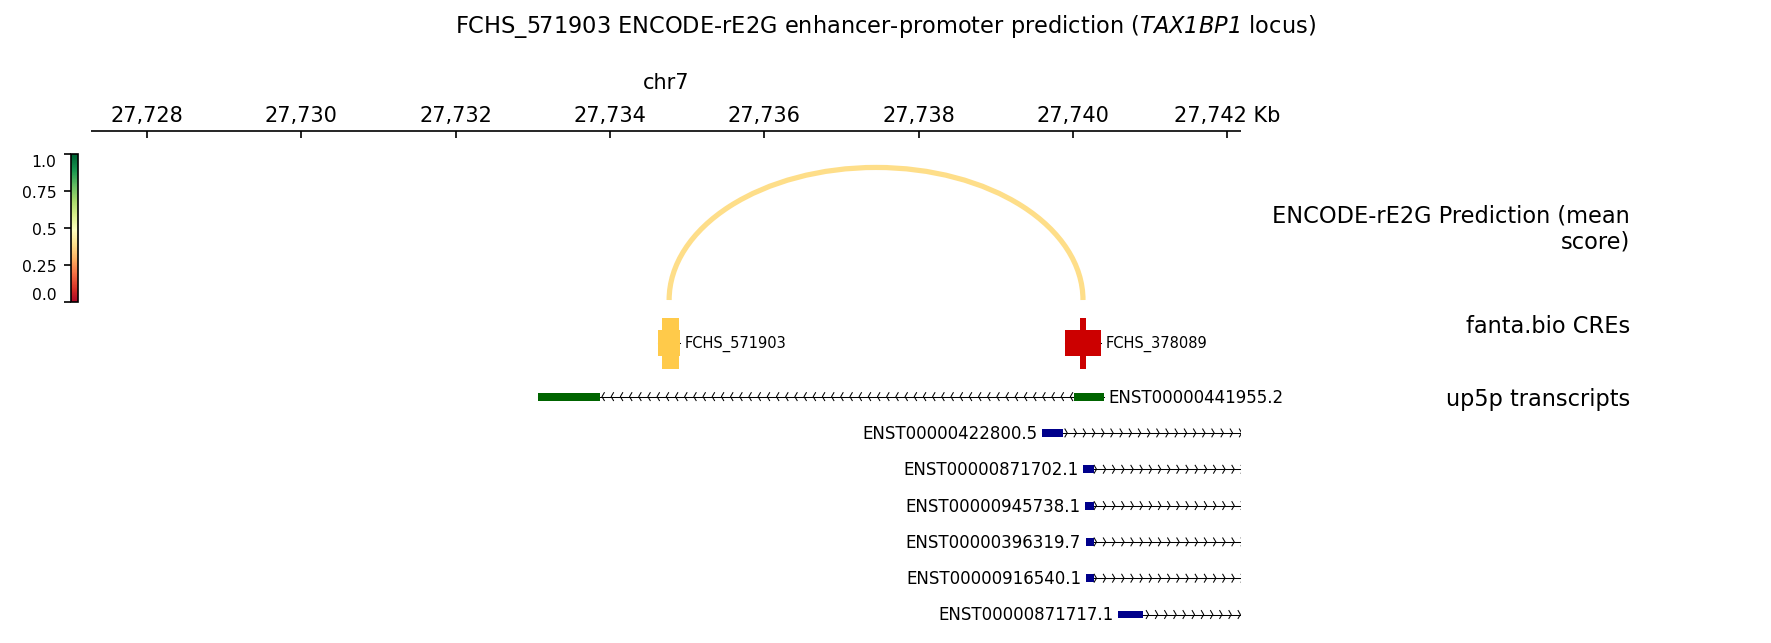

In [28]:
# Arcs on top, CRE anchors in the middle, up5p transcript models at the bottom.

fchs_ini = out_dir / "FCHS_571903_tracks.ini"
fchs_png = out_dir / "FCHS_571903_re2g_up5p.png"
fchs_ini.write_text(
    f"""\
[spacer]
height = 0.9

[x-axis]
where = top
fontsize = 10

[spacer]
height = 0.15

[rE2G arcs]
file = {fchs_links.name}
title = ENCODE-rE2G Prediction (mean score)
file_type = links
links_type = arcs
use_middle = true
height = 2.5
color = RdYlGn
min_value = 0
max_value = 1
line_width = 2.5
line_style = solid
compact_arcs_level = 1

[spacer]
height = 0.2

[fanta CRE]
file = {fchs_cre_bed9.name}
title = fanta.bio CREs
file_type = bed
height = 1.0
color = bed_rgb
border_color = none
labels = true
fontsize = 7
style = UCSC
display = stacked

[spacer]
height = 0.25

[up5p transcripts]
file = {fchs_bed12.name}
title = up5p transcripts
file_type = bed
height = 4
color = bed_rgb
labels = true
all_labels_inside = true
fontsize = 8
style = UCSC
display = stacked
"""
)

# Mathtext draws digits with mathtext.rm, so both rm and it must be italic
# for $\mathrm{TAX1BP1}$ to render fully italic in the title.
fchs_mplrc = out_dir / "matplotlibrc"
fchs_mplrc.write_text(
    "mathtext.fontset : custom\n"
    "mathtext.rm : DejaVu Sans:italic\n"
    "mathtext.it : DejaVu Sans:italic\n"
)

subprocess.run(
    [
        "pyGenomeTracks",
        "--tracks",
        str(fchs_ini),
        "--region",
        f"{REGION_CHROM}:{REGION_START}-{REGION_END}",
        "--width",
        "30",
        "--dpi",
        "150",
        "--trackLabelFraction",
        "0.25",
        # The first transcript label always spills into the margin (all_labels_inside skips it),
        # so right-align track titles to keep them clear of that label.
        "--trackLabelHAlign",
        "right",
        "--outFileName",
        str(fchs_png),
        "--title",
        r"FCHS_571903 ENCODE-rE2G enhancer-promoter prediction ($\mathrm{TAX1BP1}$ locus)",
    ],
    check=True,
    cwd=out_dir,
    env={**os.environ, "MATPLOTLIBRC": str(fchs_mplrc)},
)
display(Image(filename=str(fchs_png)))

&nbsp;

&nbsp;

&nbsp;

&nbsp;

&nbsp;

&nbsp;

&nbsp;

&nbsp;

## Specific Example (2)  _`ENEMAL`_

In [30]:
ENEMAL_up5p_cre = up5p_fantabio_cre.filter(
    pl.col("HGNC_ID") == "HGNC:56747"
)

pl.Config.set_tbl_rows(6)
print(ENEMAL_up5p_cre.select("cre_id").unique())

pl.Config.set_tbl_rows(5)
display(ENEMAL_up5p_cre)

shape: (5, 1)
┌────────────┐
│ cre_id     │
│ ---        │
│ str        │
╞════════════╡
│ FCHS_73648 │
│ FCHS_73651 │
│ FCHS_73649 │
│ FCHS_73650 │
│ FCHS_73647 │
└────────────┘


transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str
"""ENST00000701343.2""",117,36,253,81,74,15,162,59,"""ENEMAL""","""HGNC:56747""","""lncRNA""","""ENSG00000289883.2""","[""basic"", ""Ensembl_canonical"", … ""TAGENE""]","""-""",4,"""URS0002A39AA9""","""ENSEMBL_GENCODE""",null,"""havana_tagene_homo_sapiens""","[""CLS3 project"", ""Assembled from PacBio CLS3 reads""]",2,"""FCHS_73647""","""chr11""",65476719,"""65477145""","""cp1@ENEMAL""","[""NR_186313.1""]","""-342""",-427,"[{""EH38E1545172"",""dELS""}, {""EH38E2964387"",""dELS""}, {""EH38E2964388"",""dELS""}]","[{""ETV6"",1990,[{""SRX11661386"",1990}, {""SRX11661388"",1839}, … {""SRX11661389"",1621}]}, {""CTCF"",1595,[{""SRX12008351"",1595}, {""SRX12008350"",1304}, … {""SRX12008355"",637}]}, … {""SNAI2"",528,[{""SRX476922"",528}]}]","[{""HS_00156135"",""H1 Cells"",""Embryonic stem cell"",""Stem cell"",""SVM""}, {""HS_00156136"",""Fetal Intestine Small"",""Small intestine"",""Intestine"",""SVM""}, … {""HS_00156140"",""Foreskin Melanocyte Primary Cells skin01"",""Prepuce"",""Skin"",""SVM""}]",null,null,0.873684,"""ELA""","""255,202,74""","""yellow"""
"""ENST00000701343.2""",117,36,253,81,74,15,162,59,"""ENEMAL""","""HGNC:56747""","""lncRNA""","""ENSG00000289883.2""","[""basic"", ""Ensembl_canonical"", … ""TAGENE""]","""-""",4,"""URS0002A39AA9""","""ENSEMBL_GENCODE""",null,"""havana_tagene_homo_sapiens""","[""CLS3 project"", ""Assembled from PacBio CLS3 reads""]",2,"""FCHS_73648""","""chr11""",65477044,"""65477442""","""cp3@ENEMAL""","[""NR_186313.1""]","""-45""",-130,"[{""EH38E2964387"",""dELS""}, {""EH38E2964388"",""dELS""}, {""EH38E2964389"",""dELS""}]","[{""SUPT5H"",2625,[{""SRX2314263"",2625}, {""SRX2314264"",2130}, … {""SRX9237234"",582}]}, {""ZNF143"",2557,[{""SRX1510971"",2557}, {""SRX1510969"",2497}]}, … {""TFAP2B"",503,[{""SRX16499958"",503}]}]","[{""HS_00156135"",""H1 Cells"",""Embryonic stem cell"",""Stem cell"",""SVM""}, {""HS_00156136"",""Fetal Intestine Small"",""Small intestine"",""Intestine"",""SVM""}, … {""HS_00156140"",""Foreskin Melanocyte Primary Cells skin01"",""Prepuce"",""Skin"",""SVM""}]","[{""hg19::chr11:65244638..65244644,-;hg_120583.1"",""hg_120583.1""}, {""hg19::chr11:65244691..65244707,-;hg_120584.1"",""hg_120584.1""}, {""hg19::chr11:65244911..65244971,-;hg_120585.1"",""hg_120585.1""}]","[{[""chr11:65477165-65477832""]}]",-0.817112,"""ELA""","""255,202,74""","""yellow"""
"""ENST00000701343.2""",117,36,253,81,74,15,162,59,"""ENEMAL""","""HGNC:56747""","""lncRNA""","""ENSG00000289883.2""","[""basic"", ""Ensembl_canonical"", … ""TAGENE""]","""-""",4,"""URS0002A39AA9""","""ENSEMBL_GENCODE""",null,"""havana_tagene_homo_sapiens""","[""CLS3 project"", ""Assembled from PacBio CLS3 reads""]",2,"""FCHS_73649""","""chr11""",65477279,"""65477945""","""cp2@ENEMAL""","[""ENST00000701343.2"", ""NR_186313.1""]","""0""",0,"[{""EH38E2964388"",""dELS""}, {""EH38E2964389"",""dELS""}, {""EH38E2964390"",""dELS""}]","[{""MITF"",3960,[{""SRX6878446"",3960}, {""SRX6878445"",3848}, … {""SRX6878431"",506}]}, {""ZNF143"",3721,[{""SRX1510972"",3721}, {""SRX1510970"",3536}, … {""SRX14835721"",514}]}, … {""TFAP2B"",503,[{""SRX16499958"",503}]}]","[{""HS_00156135"",""H1 Cells"",""Embryonic stem cell"",""Stem cell"",""SVM""}, {""HS_00156136"",""Fetal Intestine Smal

In [35]:
ENEMAL_up5p_cre_diff_analysis = up5p_cre_diff_analysis.filter(
    pl.col("HGNC_ID") == "HGNC:56747"
)

pl.Config.set_tbl_rows(2)
display(ENEMAL_up5p_cre_diff_analysis)


transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name,cre_start,cre_end,overlap_frac_of_fantabio_cre,dpr_interval,log2fc,p_value,q_value,diff_dataset,diff_dataset_count,source_bed_file
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str,i64,i64,list[f64],list[struct[3]],list[f64],list[f64],list[f64],list[str],u32,list[str]
